# Temporal Analysis of Securitising Rhetoric

I created this notebook to produce the data and visuals I need to answer my two research questions. To recap, these are "To what extent do UK political party manifestos post-9/11 exhibit rhetorical convergence in securitising language across parties and electoral cycles?" (with rhetorical convergence meaning a narrowing of crossparty differences in either the volume or the intensity of securitising language over time) and "How do shifts in party-level securitising rhetoric relate temporally to public opinion salience on security-relevant issues and to a curated set of securitising legislation criticised as restrictive of civil liberties?"

To tackle this I run the final (full aux) model over the entire 2005-2024 corpus to generate predictions. I aggregate that to the party-election level and then filter to sentences passing the composite exceedance rate, which I set through careful bottom-up examination of different thresholds (full details in my paper). I create various visuals from this rate to examine how it rate changes between parties and over time to adress my first research question.

Then, to address my second research question, I analyse it against two external data sources, namely the Ipsos Issues Index and a timeline of securitising legislation classified by Copenhagen School sector designed by myself for this study. My analysis of this data can be found in Sections 4 and 5 of my paper.

## Use of Generative AI
In this notebook I used generative AI (Claude Sonnet 4.6 specifically) to help me:
- reformat the visuals I produced so that they fit more comfortably in the ieee overleaf 1/2 col layout (which was quite tricky for the bigger visuals like my heatmap)
- select the colours and markers for the figures so that they'd be compatible with ieee accessibility & greyscale standards 
- pick out all the parts from my model inference code that weren't necessary (i.e. all my comments and anywhere where the structure was longer than it needed to be) so I could add the ability to run infernece to this notebook (so I could have just one file for the temporal analysis) without having it take up a big amount of space and draw attention away from what I want to showcase most, which are the visualisations and tables.

However, all of the actual logic I have in this file is my own, including the choice and style of the visualisations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from scipy.stats import spearmanr, pearsonr
import warnings
warnings.filterwarnings('ignore')

# these are for the inference, so can just comment-out if I don't run it
import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from tqdm import tqdm

In [2]:
# only really need GPU for inference, temporal analysis could just run on CPU
device= torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
# these are my filepaths & threshold for this analysis
securitisation_regressor_model_params= {
    "run_inference_on_corpus": False, # to re-run inference I just set this to True
    "sec_regr_model_name": "microsoft/deberta-v3-base",
    "full_manif_corpus_filepath": "full_manifesto_corpus_for_inference.parquet",
    "chosen_model_weights_filepath": "final_securitisation_classifier_full_aux.pt",
    "inference_batch_size": 32,
    "head_dropout": 0.3,
    "permissible_len": 256,
    "num_dropout_samples": 2,
}
temporal_config= {
    "exceedance_threshold": 0.14,
    "predictions_path": "corpus_sentence_predictions_full_aux.parquet",
    "ipsos_path": "ipsos_securitisation_analysis.csv",
    "legislation_path": "uk_securitising_legislation_sectors.csv",
}

### Corpus Inference
This runs the full aux model over the corpus to produce sentence-level predictions for each dimension. I designed this part so it can be toggled on/off, as running inference takes ages so the code can skip this and just load in the results of previous inference otherwise to get straight to the temporal analysis.

In [5]:
# the full implementation of my model can be found in the actual model file I upload
# I'm keeping this as the bare minimum to run inference so I can avoid repeating myself with my explanations I put in that file.
if securitisation_regressor_model_params["run_inference_on_corpus"]== False:
    def mean_pool(token_embeddings, attention_mask):
        padding_mask_expanded= attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        return torch.sum(token_embeddings * padding_mask_expanded, dim=1) / \
               torch.clamp(padding_mask_expanded.sum(dim=1), min=1e-9)
    
    class MultiSampleDropoutHead(nn.Module):
        def __init__(self, hidden_size, dropout_prob, num_samples):
            super().__init__()
            self.num_samples= num_samples
            self.ln= nn.LayerNorm(hidden_size)
            self.dropouts= nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(num_samples)])
            self.fc1= nn.Linear(hidden_size, hidden_size // 2)
            self.activation= nn.GELU()
            self.fc2= nn.Linear(hidden_size // 2, 1)
        def forward(self, head_input):
            head_input= self.ln(head_input)
            per_sample_outputs= [self.fc2(self.activation(self.fc1(dropout_layer(head_input)))) for dropout_layer in self.dropouts]
            return torch.sigmoid(torch.stack(per_sample_outputs).mean(dim=0))
    
    class FullAuxModel(nn.Module):
        def __init__(self, model_name, dropout, num_samples):
            super().__init__()
            self.encoder= AutoModel.from_pretrained(model_name, use_safetensors=True)
            encoder_hidden_size= self.encoder.config.hidden_size
            self.dropout= nn.Dropout(dropout)
            self.threat_head= MultiSampleDropoutHead(encoder_hidden_size, dropout, num_samples)
            self.urgency_head= MultiSampleDropoutHead(encoder_hidden_size, dropout, num_samples)
            self.justification_head= MultiSampleDropoutHead(encoder_hidden_size, dropout, num_samples)
            self.aux_threat_head= MultiSampleDropoutHead(encoder_hidden_size, dropout, num_samples)
            self.aux_urgency_head= MultiSampleDropoutHead(encoder_hidden_size, dropout, num_samples)
            self.aux_justification_head= MultiSampleDropoutHead(encoder_hidden_size, dropout, num_samples)
        def forward(self, input_ids, attention_mask):
            encoder_output= self.encoder(input_ids=input_ids, attention_mask=attention_mask)
            mean_pooled_repr= self.dropout(mean_pool(encoder_output.last_hidden_state, attention_mask))
            predicted_dimension_scores= torch.cat([self.threat_head(mean_pooled_repr), self.urgency_head(mean_pooled_repr), self.justification_head(mean_pooled_repr)], dim=1)
            return {"logits": predicted_dimension_scores}

    class InferenceDataset(Dataset):
        def __init__(self, texts, tokenizer, max_len):
            self.texts= texts
            self.tokenizer= tokenizer
            self.max_len= securitisation_regressor_model_params["permissible_len"]
        def __len__(self): return len(self.texts)
        def __getitem__(self, idx):
            tokenised_encoding= self.tokenizer(str(self.texts[idx]), padding="max_length", truncation=True, max_length=self.max_len, return_tensors="pt")
            return {field_name: field_tensor.squeeze(0) for field_name, field_tensor in tokenised_encoding.items()}

    corpus_df= pd.read_parquet(securitisation_regressor_model_params["full_manif_corpus_filepath"])
    model= FullAuxModel(securitisation_regressor_model_params["sec_regr_model_name"], securitisation_regressor_model_params["head_dropout"], securitisation_regressor_model_params["num_dropout_samples"])
    model.load_state_dict(torch.load(securitisation_regressor_model_params["chosen_model_weights_filepath"], map_location=device, weights_only=True))
    model.to(device).eval()
    tokenizer= AutoTokenizer.from_pretrained(securitisation_regressor_model_params["sec_regr_model_name"], use_fast=False)

    dataset= InferenceDataset(corpus_df["sentence_text"].tolist(), tokenizer, securitisation_regressor_model_params["permissible_len"])
    loader= DataLoader(dataset, batch_size=securitisation_regressor_model_params["inference_batch_size"], shuffle=False)
    all_preds= []
    with torch.no_grad():
        for batch in tqdm(loader, desc="Inference"):
            input_token_ids= batch["input_ids"].to(device)
            input_attention_mask= batch["attention_mask"].to(device)
            batch_dimension_preds= model(input_ids=input_token_ids, attention_mask=input_attention_mask)["logits"].cpu().numpy()
            all_preds.append(batch_dimension_preds)
    all_preds= np.vstack(all_preds)

    corpus_df["pred_threat"]= all_preds[:, 0]
    corpus_df["pred_urgency"]= all_preds[:, 1]
    corpus_df["pred_justification"]= all_preds[:, 2]
    corpus_df["pred_composite"]= corpus_df[["pred_threat", "pred_urgency", "pred_justification"]].min(axis=1)
    corpus_df.to_parquet(temporal_config["predictions_path"], index=False)

Inference: 100%|██████████| 1429/1429 [22:03<00:00,  1.08it/s]


### Reading in inference
Now all inference results are read in & preprocessed here.
If the above was ran this can be skipped/commented out, though it won't hurt either way.

In [21]:
corpus_df= pd.read_parquet(temporal_config["predictions_path"])
if "partyname" in corpus_df.columns:
    corpus_df["party_name"]= corpus_df["party_name"].fillna(corpus_df["partyname"])
    corpus_df= corpus_df.drop(columns=["partyname"])

print(f"Great, got all the data. Overall that's loaded {len(corpus_df):,} sentences with predictions.")
print(f"\nThe present parties I have for analysing are: {sorted(corpus_df['party_name'].dropna().unique())}")

Great, got all the data. Overall that's loaded 45,722 sentences with predictions.

The present parties I have for analysing are: ['Alliance Party of Northern Ireland', 'Conservative Party', 'Democratic Unionist Party', 'Green Party of England and Wales', 'Labour Party', 'Liberal Democrats', 'Reform UK', 'Scottish National Party', 'Social Democratic and Labour Party', 'The Party of Wales', 'Traditional Unionist Voice', 'Ulster Unionist Party', 'United Kingdom Independence Party', 'We Ourselves']


In [7]:
# now I've loaded the parties in I filter out stub sentences that shouldn't have been scored, like single words, nums-only & v. short fragments from OCR artefacts
rows_before_filter= len(corpus_df)
word_counts= corpus_df["sentence_text"].astype(str).str.split().str.len()
is_numeric_only= corpus_df["sentence_text"].astype(str).str.strip().str.match(r'^\d+$')
corpus_df= corpus_df[(word_counts >= 3) & (~is_numeric_only)].copy()
print(f"gotten rid of {rows_before_filter - len(corpus_df):,} stub sentences.")
print(f"the corpus went from {rows_before_filter:,} sentences to {len(corpus_df):,} ones.")

# this is the part where I compute the exceedance rate from the composite & aggregate it to the party-election level
threshold= temporal_config["exceedance_threshold"]
corpus_df["above_threshold"]= (corpus_df["pred_composite"] >= threshold).astype(int)

party_election_agg= corpus_df.groupby(["party_name", "election_year"]).agg(
    exceedance_rate=("above_threshold", "mean"), mean_threat=("pred_threat", "mean"), mean_urgency=("pred_urgency", "mean"), mean_justification=("pred_justification", "mean"), 
    mean_composite=("pred_composite", "mean"), sentence_count=("pred_composite", "count"),).reset_index()
party_election_agg= party_election_agg.rename(columns={"party_name": "party"})

print(f"Now the aggregation to party-election lvl has been done, which gives {len(party_election_agg)} observations to work with.")
print(f"I used an exceedance threshold of {threshold} for that.")
print(f"The mean exceedance rate for each party-election is at {party_election_agg.exceedance_rate.mean()*100:.2f}%")
# I display this as a quick reference for the df I'm using in the next parts
party_election_agg[["party", "election_year", "exceedance_rate", "sentence_count"]].sort_values(["party", "election_year"])

gotten rid of 39 stub sentences.
the corpus went from 45,722 sentences to 45,683 ones.
Now the aggregation to party-election lvl has been done, which gives 75 observations to work with.
I used an exceedance threshold of 0.14 for that.
The mean exceedance rate for each party-election is at 1.68%


,party,election_year,exceedance_rate,sentence_count
0,Alliance Party of Northern Ireland,2005,0.010323,775
1,Alliance Party of Northern Ireland,2010,0.009105,659
2,Alliance Party of Northern Ireland,2015,0.016502,606
3,Alliance Party of Northern Ireland,2017,0.012422,483
4,Alliance Party of Northern Ireland,2019,0.018149,551
...,...,...,...,...
70,We Ourselves,2010,0.016260,738
71,We Ourselves,2015,0.022422,223
72,We Ourselves,2017,0.000000,251
73,We Ourselves,2019,0.000000,106


In [22]:
# here I'm exporting sentences meeting the threshold for manual inspection to verify the
# model is identifying genuine securitising language, not false positives
high_composite_sentences= corpus_df[corpus_df["pred_composite"] >= threshold].copy()
high_composite_sentences= high_composite_sentences.sort_values("pred_composite", ascending=False)
review_cols= ["party_name", "election_year", "sentence_text",
              "pred_composite", "pred_threat", "pred_urgency", "pred_justification"]
high_composite_sentences= high_composite_sentences[review_cols]

print(f"across the whole corpus, sentences with composite >= {threshold} are at {len(high_composite_sentences):,} / {len(corpus_df):,}")
print(f"(which is {100*len(high_composite_sentences)/len(corpus_df):.1f}%)\n")

high_composite_sentences.to_excel("high_composite_sentences_for_review.xlsx", index=False)
print("high_composite_sentences_for_review.xlsx has now been saved for manual review (for calibrating the threshold).")


across the whole corpus, sentences with composite >= 0.14 are at 747 / 45,722
(which is 1.6%)

high_composite_sentences_for_review.xlsx has now been saved for manual review (for calibrating the threshold).


## Configuration

I do all my data formatting setup for the visuals I use here. Elections, party colours, sector mappings & the incumbent government for each electoral cycle are all coloured as consistently as I could make them. I included the incumbent mapping because the rhetoric-legislation comparison I make in my paper's Section 5.2 uses the governing party's manifesto score, since UK legislation requires government sponsorship and a Commons majority.

In [9]:
# loading external data
ipsos_df= pd.read_csv(temporal_config["ipsos_path"], parse_dates=["date"])
legislation_df= pd.read_csv(temporal_config["legislation_path"])
legislation_df= legislation_df[(legislation_df["CS Sector"] != "EXCLUDED")].copy() # (I had some acts that were interesting but I couldn't justify as securitsing, so I had to leave them out using this marker)
legislation_df["Royal_Assent_Date"]= pd.to_datetime(legislation_df["Royal_Assent_Date"])
legislation_df["year"]= legislation_df["Royal_Assent_Date"].dt.year
print(f"the ipsos data for the study has {len(ipsos_df)} rows, and the securitising legislation timeline I made for this study has {len(legislation_df)} Acts inside the study window")

elections= [2005, 2010, 2015, 2017, 2019, 2024]
# I needed to keep the election metadata, which is namely the election dates & the party that came into power after each
election_metadata= {
    2005: {"date": "2005-05-05", "incumbent": "Labour Party"},
    2010: {"date": "2010-05-06", "incumbent": "Conservative Party"},
    2015: {"date": "2015-05-07", "incumbent": "Conservative Party"},
    2017: {"date": "2017-06-08", "incumbent": "Conservative Party"},
    2019: {"date": "2019-12-12", "incumbent": "Conservative Party"},
    2024: {"date": "2024-07-04", "incumbent": "Labour Party"}}

# I represent the election dates as timestamps here which I use for the inter-election period calcluation
# so that Acts that got assent early in an election year are connected to the right inter-election period instead of the just paintbrushing an act to the year it was enacted
election_dates= {yr: pd.Timestamp(meta["date"]) for yr, meta in election_metadata.items()}

# I tried picking out colours that match the parties where I could, but especially for the major ones I had to ensure they were colour-blind & accessibly friendly for my paper
party_colours= { 
    "Conservative Party": "#0087DC", "Labour Party": "#E4003B",
    "Liberal Democrats": "#FAA61A",
    "Scottish National Party": "#C09000",
    "Green Party of England and Wales": "#00B140",
    "United Kingdom Independence Party": "#6D3177",
    "Reform UK": "#12B6CF",
    "The Party of Wales": "#005B54",
    "Democratic Unionist Party": "#D46A4C",
    "Alliance Party of Northern Ireland": "#F6CB2F",
    "Social Democratic and Labour Party": "#2AA82C",
    "Ulster Unionist Party": "#9999FF",
    "Traditional Unionist Voice": "#0C3A6A",
    "We Ourselves": "#408080"}

# I use different markers for greyscale distinguishability so I comply w/ IEEE formats on my visuals
party_markers= {
    "Conservative Party": "s", "Labour Party": "o",
    "Liberal Democrats": "^", "Scottish National Party": "D",
    "Green Party of England and Wales": "v", "The Party of Wales": "P",
    "Democratic Unionist Party": "X", "United Kingdom Independence Party": "p",
    "Reform UK": "*", "Alliance Party of Northern Ireland": "h",
    "Social Democratic and Labour Party": "d", "Ulster Unionist Party": ">",
    "Traditional Unionist Voice": "<", "We Ourselves": "H",}
light_colour_parties= {"Scottish National Party", "Alliance Party of Northern Ireland"}

# I set the copenhagen school sector colours for legislation markers to align with the ipsos colours I'm using
sector_colours= {"Military": "#C0392B", "Societal": "#8E44AD", "Political": "#2980B9", "Economic": "#E67E22", "Environmental": "#27AE60",}
# here I map ipsos cols to CS sectors
cs_ipsos_mapping= {"Military": "def_pct", "Societal": "imm_pct", "Environmental": "pol_pct", "Economic": "eco_pct", "Political": "com_pct",}

# these are the parties present at all 6 elections (a consistent subset for my convergence analysis)
party_election_counts= party_election_agg.groupby("party")["election_year"].apply(set)
consistent_parties= sorted(party for party, yrs in party_election_counts.items() if set(elections).issubset(yrs) and party != "Democratic Unionist Party") # (I excluded that one because it wasn't present in all the elections)
all_parties= sorted(party_election_agg.party.unique())
print(f"There are {len(consistent_parties)} consistent parties for me to analyse, which are: {consistent_parties}")

# for my composite exceedance rate plot in 5.1 I have 2 "tiers", i.e. the primary tier of the 4 majors and the secondary tier of all the rest in light grey
tier_1_parties= [party for party in consistent_parties if party in {"Conservative Party", "Labour Party", "Liberal Democrats", "Scottish National Party"}]
tier_2_parties= [party for party in all_parties if party not in tier_1_parties]

the ipsos data for the study has 311 rows, and the securitising legislation timeline I made for this study has 24 Acts inside the study window
There are 10 consistent parties for me to analyse, which are: ['Alliance Party of Northern Ireland', 'Conservative Party', 'Green Party of England and Wales', 'Labour Party', 'Liberal Democrats', 'Scottish National Party', 'Social Democratic and Labour Party', 'The Party of Wales', 'Ulster Unionist Party', 'We Ourselves']


## Election windows

For each general election I calculate rhetoric aggregates, the incumbent's exceedance rate & the opposition mean to create a single summary row per election that I use in my paper's heatmap.


In [10]:
# 1 row per election that has in it all the rhetoric aggregates & incumbent score
election_window_rows= []
for yr, elec_meta in election_metadata.items():
    election_date= pd.Timestamp(elec_meta["date"])
    row= {"election_year": yr, "incumbent": elec_meta["incumbent"]}

    # this is where I get the rhetoric aggregates for the consistent party subset
    consistent_at_election= party_election_agg[(party_election_agg.party.isin(consistent_parties)) & (party_election_agg.election_year == yr)]
    row["rhetoric_consistent_mean"]= consistent_at_election["exceedance_rate"].mean()
    row["rhetoric_consistent_sd"]= consistent_at_election["exceedance_rate"].std()

    # that's the incumbent party's own exceedance rate (specifically necessary for the table I report in S5 of my paper)
    incumbent_row= party_election_agg[(party_election_agg.party == elec_meta["incumbent"]) & (party_election_agg.election_year == yr)]
    row["rhetoric_incumbent"]= incumbent_row["exceedance_rate"].values[0] if len(incumbent_row) else np.nan
    # & opposition mean too (which is consistent parties - incumbent)
    opposition_rows= consistent_at_election[consistent_at_election.party != elec_meta["incumbent"]]
    row["rhetoric_opposition_mean"]= opposition_rows["exceedance_rate"].mean() if len(opposition_rows) else np.nan
    election_window_rows.append(row)
election_windows= pd.DataFrame(election_window_rows)

## Figures 1 & 2: Party securitisation trajectories & their dimensional decomposition

I plot each party's composite exceedance rate across six electoral cycles to create first first figure I directly use in my analysis. Major parties (Con, Lab, LD, SNP) get bold lines w/ distinct markers for greyscale readability, and the other parties are drawn on thinly in grey to help interpretation of the majors in context.

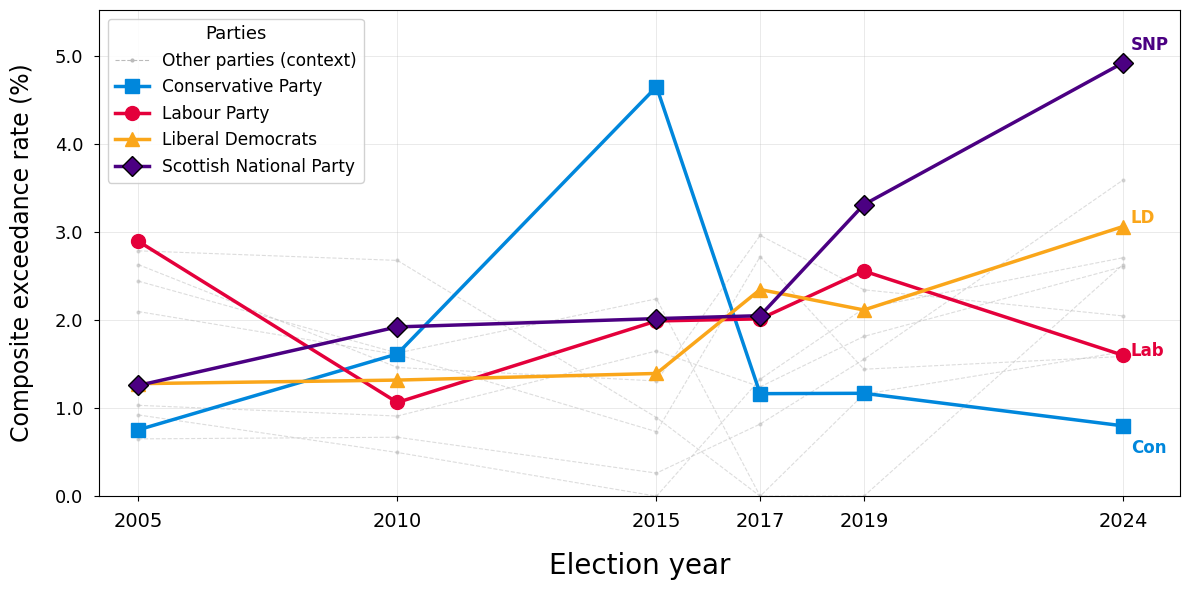

great, that first figure is now saved in this directory as fig1_party_trajectories.pdf


In [23]:
fig, ax = plt.subplots(figsize=(12, 6))

# I had to override my original darker yellow for SNP w/ this purple because the light yellow of lib dems clashed quite bad
party_colour_overrides = {"Scottish National Party": "#4B0082"}
def party_line_colour(party):
    return party_colour_overrides.get(party, party_colours.get(party, "#333333"))

# these are the context lines for the wider parliamentary field (i.e. non-major parties)
tier_2_line_colour = "#BBBBBB"
tier_2_consistent = [party for party in tier_2_parties if party_election_agg[party_election_agg.party == party].election_year.nunique() == 6]
for party in tier_2_consistent:
    sub = party_election_agg[party_election_agg.party == party].sort_values("election_year")
    if len(sub) < 2:
        continue
    ax.plot(sub.election_year, sub.exceedance_rate * 100, color=tier_2_line_colour, marker=".", markersize=4, linewidth=0.8, alpha=0.5, linestyle="--", zorder=2)

# i have this empty entry just so "other parties" shows up in the legend
ax.plot([], [], color=tier_2_line_colour, linewidth=0.8, linestyle="--", marker=".", markersize=4, label="Other parties (context)")

# main four
for party in tier_1_parties:
    sub = party_election_agg[party_election_agg.party == party].sort_values("election_year")
    colour = party_line_colour(party)
    marker = party_markers.get(party, "o")
    edge_colour = "black" if party in light_colour_parties else colour
    ax.plot(sub.election_year, sub.exceedance_rate * 100, color=colour, marker=marker, markersize=10, markeredgecolor=edge_colour, markeredgewidth=1.0, linewidth=2.5, label=party, zorder=5)

# I also added on these inline short labels at 2024 to improve readability w/ the legend a bit
party_label_short = {"Conservative Party": "Con", "Labour Party": "Lab", "Liberal Democrats": "LD", "Scottish National Party": "SNP"}
# I have these slight vertical nudges too to stop them overlapping
party_label_y_offsets = {"Conservative Party": -0.25, "Labour Party": 0.05,"Liberal Democrats": 0.10, "Scottish National Party": 0.20,}

for party in tier_1_parties:
    sub = party_election_agg[party_election_agg.party == party].sort_values("election_year")
    if len(sub) == 0:
        continue
    last_row = sub.iloc[-1]
    colour = party_line_colour(party)
    ax.annotate(party_label_short[party], xy=(last_row.election_year, last_row.exceedance_rate*100), xytext=(last_row.election_year+0.15, last_row.exceedance_rate*100 + party_label_y_offsets[party]), fontsize=12, fontweight="bold", color=colour, va="center", zorder=6)

ax.set_xlabel("Election year", fontsize=20, labelpad=15)
ax.set_ylabel("Composite exceedance rate (%)", fontsize=17, labelpad=15)
ax.set_xticks(elections)
ax.tick_params(axis='x', labelsize=14, pad=8)
ax.tick_params(axis='y', labelsize=13, pad=8)
ax.set_xlim(2004.25, 2025.1) # had to tighten the right margin here because was too much whitespace for the ieee 1/2 col layout
data_max = party_election_agg[party_election_agg.party.isin(tier_1_parties)].exceedance_rate.max() * 100
ax.set_ylim(0, data_max + 0.6)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))
ax.legend(loc="upper left", fontsize=12.25, title="Parties", title_fontsize=13, framealpha=0.9)
ax.grid(alpha=0.3, linewidth=0.6)
plt.tight_layout()
plt.savefig("fig1_party_trajectories.pdf", dpi=300, bbox_inches="tight")
plt.show()
print("great, that first figure is now saved in this directory as fig1_party_trajectories.pdf")

In [12]:
# now I do aggregation over above-threshold sentences only for dimensional decomposition
above_threshold_sentences = corpus_df[corpus_df["pred_composite"] >= threshold].copy()
above_threshold_agg = above_threshold_sentences.groupby(["party_name", "election_year"]).agg(n_above_threshold=("pred_composite", "count"), mean_threat=("pred_threat", "mean"), mean_urgency=("pred_urgency", "mean"),mean_justification=("pred_justification", "mean")).reset_index().rename(columns={"party_name": "party"})

# this maps my subplot titles to their corresponding col in above_threshold_agg
dimension_to_column = {"Threat": "mean_threat", "Urgency": "mean_urgency", "Justification": "mean_justification"}

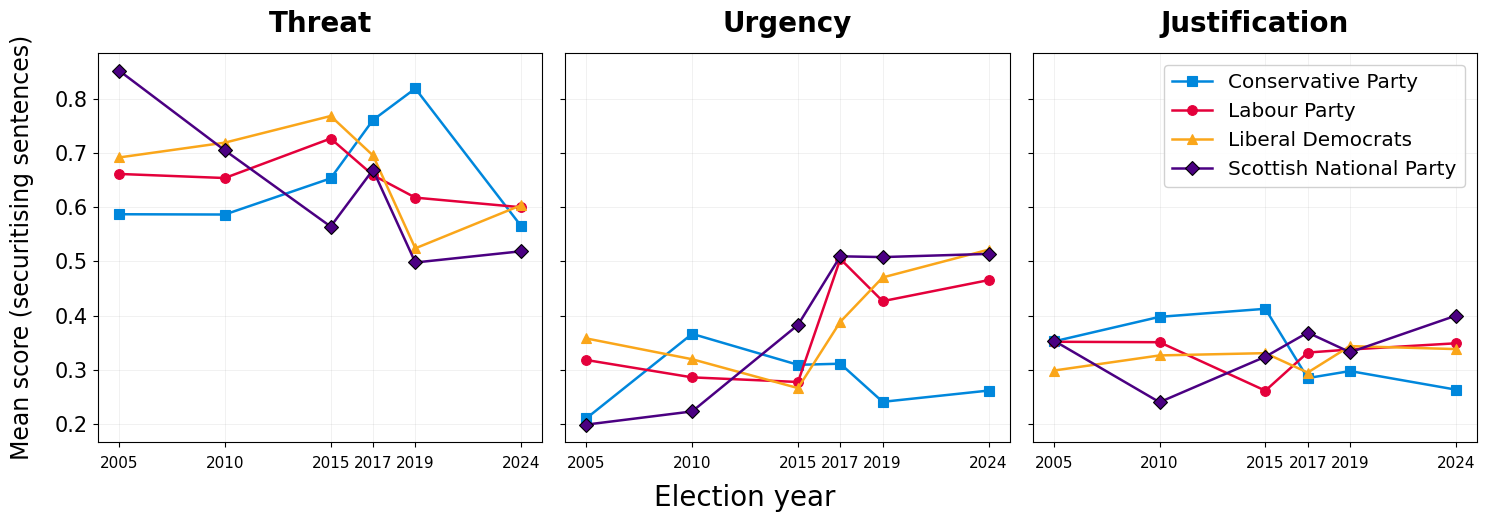

perfect, now the second figure is saved in this directory as fig2_dimension_decomposition.pdf


In [24]:
# This next bit is the per-dimension decomposition of the above-threshold sentences
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True) # I changed height here which slightly squashed it but it fits better
for axis_idx, (dimension_label, column_name) in enumerate(dimension_to_column.items()):
    ax= axes[axis_idx]
    # majors only here, and they get plotted using the cell above's aggregate of above-thresholds
    for party in tier_1_parties:
        sub= above_threshold_agg[above_threshold_agg.party == party].sort_values("election_year")
        colour= party_line_colour(party)
        marker= party_markers.get(party, "o")
        edge_colour= "black" if party in light_colour_parties else colour
        ax.plot(sub.election_year, sub[column_name], color=colour, marker=marker, markersize=7, markeredgecolor=edge_colour, markeredgewidth=0.8, linewidth=1.8, label=party)

    ax.set_title(dimension_label, fontsize=20, fontweight="bold", pad=15)
    ax.set_xticks(elections)
    ax.set_xlim(2004, 2025)
    ax.tick_params(axis='x', labelsize=11, pad=6)
    ax.tick_params(axis='y', labelsize=15)
    ax.grid(alpha=0.25, linewidth=0.5)

axes[0].set_ylabel("Mean score (securitising sentences)", fontsize=17, labelpad=15)
axes[2].legend(fontsize=14.4, loc="upper right", framealpha=0.9, bbox_to_anchor=(0.995, 0.995))
fig.supxlabel("Election year", fontsize=20, y=0.06)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("fig2_dimension_decomposition.pdf", dpi=300, bbox_inches="tight")
plt.show()
print("perfect, now the second figure is saved in this directory as fig2_dimension_decomposition.pdf")

## Figure 3: Party-election intensity heatmap

Now I create the heatmap used in my paper to allow for the cross-party pattern to be quickly viewed and interpreted. Grey cells show elections where
a party did not stand.

### The Acts-enacted row
That row show how many securitising Acts were given Royal Assent (i.e. enacted) in the inter-election period ending at each election. "Preceding period" just means the stretch of time between the previous election & the one labelled on that col.

I count an Act as being under a given election if its Royal Assent date is inside the window that ends on that election, not the window that starts from it, so the 11 Acts shown under 2024 are the ones passed during the 2019–2024 parliament and the 6 Acts under 2010 are the ones that passed during Labour's 2005–2010 term.

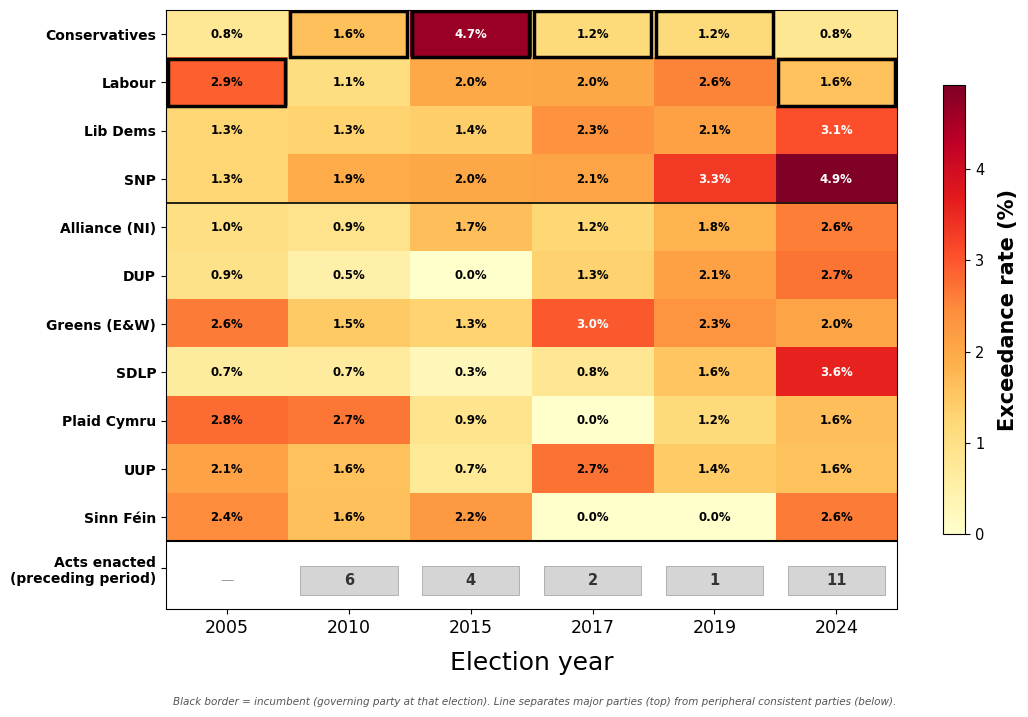

perfect, now fig 3 is also saved as fig3_heatmap_incumbent.pdf in this directory


In [26]:
# my consistent party set w/ majors first then any other party that shows up at all 6 elections
major_parties_ordered = ["Conservative Party", "Labour Party", "Liberal Democrats", "Scottish National Party"]
other_consistent_parties= sorted(p for p in all_parties if p not in major_parties_ordered and party_election_agg[party_election_agg.party == p].election_year.nunique() == 6)
parties_for_heatmap= major_parties_ordered + other_consistent_parties

party_short_names= { # partynames are too long to fit on the ieee 1/2 col layout for this img so I need to shorten them
    "Conservative Party": "Conservatives",
    "Labour Party": "Labour",
    "Liberal Democrats": "Lib Dems",
    "Scottish National Party": "SNP",
    "Green Party of England and Wales": "Greens (E&W)",
    "Alliance Party of Northern Ireland": "Alliance (NI)",
    "Social Democratic and Labour Party": "SDLP",
    "Democratic Unionist Party": "DUP",
    "Ulster Unionist Party": "UUP",
    "The Party of Wales": "Plaid Cymru",
    "We Ourselves": "Sinn Féin",
}

# now I build the heatmap matrix row by row. 
heatmap_rows= []
for party in parties_for_heatmap:
    row= {"party": party}
    for yr in elections: # nan instances is just that a party didn't contest that election
        matched_exceedance= party_election_agg[(party_election_agg.party == party) & (party_election_agg.election_year == yr)]["exceedance_rate"]
        row[yr]= matched_exceedance.values[0] * 100 if len(matched_exceedance) else np.nan
    heatmap_rows.append(row)

# legislation counts per inter-election period. 2005 gets 0 as there's no preceding window in the study
legislation_counts_by_election_year= {elections[0]: 0}
for i in range(len(elections) - 1):
    start_yr, end_yr= elections[i], elections[i + 1]
    start_date, end_date= election_dates[start_yr], election_dates[end_yr]
    acts_in_period_mask= (legislation_df.Royal_Assent_Date >= start_date) & (legislation_df.Royal_Assent_Date < end_date)
    legislation_counts_by_election_year[end_yr]= int(acts_in_period_mask.sum())
legislation_footer_row= {"party": "Acts enacted\n(preceding period)"}
for yr in elections:
    legislation_footer_row[yr]= legislation_counts_by_election_year.get(yr, 0)
heatmap_rows.append(legislation_footer_row)

heatmap_df= pd.DataFrame(heatmap_rows).set_index("party")
fig, ax= plt.subplots(figsize=(11, max(4.5, len(heatmap_df) * 0.6)))
n_parties= len(heatmap_df) - 1
n_majors= len(major_parties_ordered)
heatmap_matrix= heatmap_df.values
exceedance_party_matrix= heatmap_matrix[:n_parties, :]
exceedance_party_matrix_masked= np.ma.array(exceedance_party_matrix, mask=np.isnan(exceedance_party_matrix))

# I make the cells grey for absent parties so they're easily distinguished from zero exceedance
ylororrd_with_grey_nan= plt.cm.YlOrRd.copy()
ylororrd_with_grey_nan.set_bad(color="#E0E0E0")

heatmap_image= ax.imshow(exceedance_party_matrix_masked, aspect="auto", cmap=ylororrd_with_grey_nan, vmin=0, extent=[-0.5, len(elections)-0.5, n_parties-0.5, -0.5])
ordered_party_names= list(heatmap_df.index)[:n_parties]
for i in range(n_parties):
    for j in range(len(elections)):
        cell_val= exceedance_party_matrix[i, j]
        yr= elections[j]
        party_name= ordered_party_names[i]

        if not np.isnan(cell_val):
            # I flip to white text on dark cells so it stays legible across the whole colour range
            cell_text_colour= "white" if cell_val > (exceedance_party_matrix[~np.isnan(exceedance_party_matrix)].max() * 0.6) else "black"
            ax.text(j, i, f"{cell_val:.1f}%", ha="center", va="center", fontsize=8.5, fontweight="bold", color=cell_text_colour)
        else:
            ax.text(j, i, "\u2014", ha="center", va="center", fontsize=8.5, color="#999")

        # I put a black border to mark the incumbent at each election, which is also useful for my RQ2 legislative comparison
        if yr in election_metadata and election_metadata[yr]["incumbent"] == party_name:
            ax.add_patch(plt.Rectangle((j - 0.48, i - 0.48), 0.96, 0.96, facecolor="none", edgecolor="black", linewidth=2.5, zorder=10))

# i also added a line in to seperate majors from smaller parties
ax.axhline(n_majors - 0.5, color="black", linewidth=1.2, linestyle="-")
legislation_footer_row_y= n_parties + 0.3
ax.axhline(n_parties - 0.5, color="black", linewidth=1.5)

for j, yr in enumerate(elections):
    acts_count= int(heatmap_matrix[n_parties, j])
    if acts_count > 0:
        ax.add_patch(plt.Rectangle((j - 0.4, legislation_footer_row_y - 0.3), 0.8, 0.6, facecolor="#D5D5D5", edgecolor="#999", linewidth=0.5))
        ax.text(j, legislation_footer_row_y, str(acts_count), ha="center", va="center", fontsize=10.5, fontweight="bold", color="#333")
    else:
        ax.text(j, legislation_footer_row_y, "\u2014", ha="center", va="center", fontsize=9.5, color="#999")

short_tick_labels= [party_short_names.get(p, p) for p in ordered_party_names]
ax.set_xticks(range(len(elections)))
ax.set_xticklabels(elections, fontsize=12.5)
ax.set_yticks(list(range(n_parties)) + [n_parties + 0.05])
ax.set_yticklabels(short_tick_labels + ["Acts enacted\n(preceding period)"], fontsize=10, fontweight="bold")
ax.set_ylim(n_parties + 0.9, -0.5)
ax.set_xlabel("Election year", fontsize=18, labelpad=10)

exceedance_colourbar= plt.colorbar(heatmap_image, ax=ax, shrink=0.75)
exceedance_colourbar.set_label("Exceedance rate (%)", fontsize=15, fontweight="bold", labelpad=10)
exceedance_colourbar.ax.tick_params(labelsize=10.5)
ax.text(0.01, -0.16, "Black border = incumbent (governing party at that election). Line separates major parties (top) from peripheral consistent parties (below).", transform=ax.transAxes, fontsize=7.5, color="#555", style="italic")

plt.tight_layout()
plt.savefig("fig3_heatmap_incumbent.pdf", dpi=300, bbox_inches="tight")
plt.show()
print("perfect, now fig 3 is also saved as fig3_heatmap_incumbent.pdf in this directory")

## Figure 4: Incumbent rhetoric, public opinion salience & securitising legislation

This visual is what I use to answer my 2nd research question. I plot for each inter-election period the Ipsos issues series for each of the 5 securitisation sectors, and underneath add rug ticks to show the Acts that got royal assent during it. This lets me compare co-occurences of opinion salience with securitising legislation and then interpret that in a wider sense wrt the above.

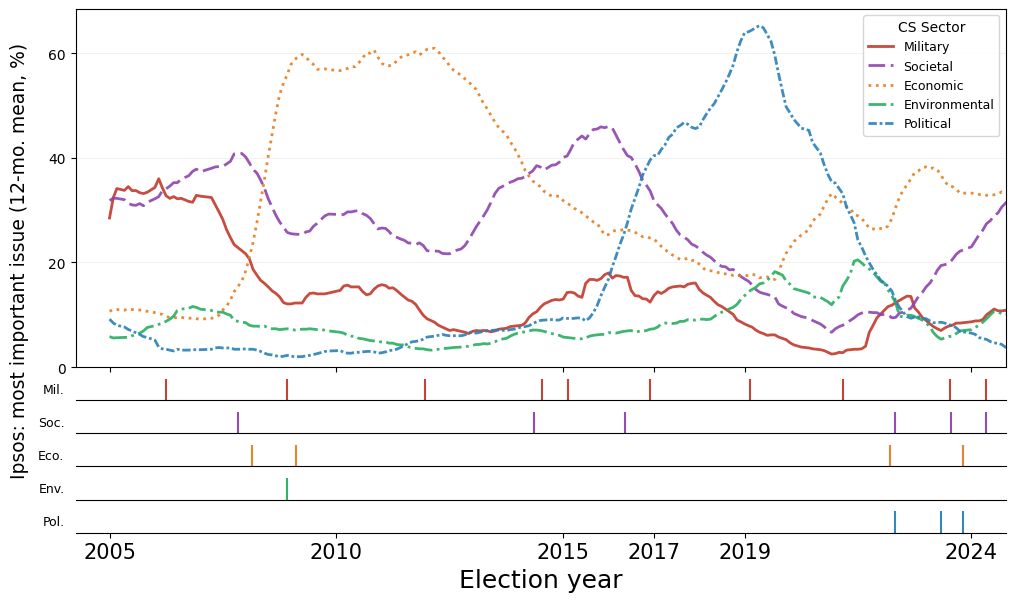

good, also saved fig4 here as fig4_option_C_stacked_strips.pdf


In [28]:
sector_plot_order= ["Military", "Societal", "Economic", "Environmental", "Political"]

fig, all_axes= plt.subplots(6, 1, figsize=(12, 6.8), sharex=True, gridspec_kw={"height_ratios": [5, 0.3, 0.3, 0.3, 0.3, 0.3], "hspace": 0.15})

main_ipsos_ax= all_axes[0]
legislation_strip_axes= all_axes[1:]

# I added this line styling so it would be visible even in greyscale
sector_linestyles= {"Military": "-", "Societal": (0, (6, 2)), "Economic": ":", "Environmental": "-.", "Political": (0, (3, 1, 1, 1))}

smoothing_window_months= 12
ipsos_in_study_window= ipsos_df[(ipsos_df.date >= "2005-01-01") & (ipsos_df.date <= "2025-01-01")].copy().sort_values("date").reset_index(drop=True)
ipsos_in_study_window["year_decimal"]= ipsos_in_study_window["date"].dt.year + (ipsos_in_study_window["date"].dt.dayofyear - 1) / 365.25

# I plot 5 ipsos sectors for the 5 corresponding securitisation sectors
for sector in sector_plot_order:
    ipsos_col_for_sector= cs_ipsos_mapping[sector]
    rolling_smoothed_series= ipsos_in_study_window[ipsos_col_for_sector].rolling(window=smoothing_window_months, min_periods=4, center=True).mean()
    main_ipsos_ax.plot(ipsos_in_study_window.year_decimal, rolling_smoothed_series, color=sector_colours[sector], linewidth=2, alpha=0.9, linestyle=sector_linestyles[sector], label=sector)

# I specifically anchored my y-label low so any overflow goes down into the strip area & not above the panel to save ieee col space
main_ipsos_ax.set_ylabel("Ipsos: most important issue (12-mo. mean, %)", fontsize=13.5, labelpad=1)
main_ipsos_ax.yaxis.set_label_coords(-0.05, 0.30)
main_ipsos_ax.set_yticks([0, 20, 40, 60])
main_ipsos_ax.set_ylim(0, None)
main_ipsos_ax.grid(True, axis="y", alpha=0.3, linewidth=0.4)
main_ipsos_ax.set_xlim(2004.25, 2024.75)
main_ipsos_ax.legend(loc="upper right", fontsize=9, title="CS Sector", title_fontsize=10)
main_ipsos_ax.tick_params(labelbottom=False)

legislation_with_year_decimal= legislation_df.copy()
legislation_with_year_decimal["year_decimal"]= legislation_with_year_decimal["Royal_Assent_Date"].dt.year + (legislation_with_year_decimal["Royal_Assent_Date"].dt.dayofyear - 1) / 365.25
sector_short_labels= {"Military": "Mil.", "Societal": "Soc.", "Economic": "Eco.", "Environmental": "Env.", "Political": "Pol."} # for saving myself space on the paper again

# now for the rug ticks of legislation
for strip_idx, sector in enumerate(sector_plot_order):
    strip_ax= legislation_strip_axes[strip_idx]
    is_last_strip= (strip_idx == len(sector_plot_order) - 1)
    acts_for_sector= legislation_with_year_decimal[legislation_with_year_decimal["CS Sector"] == sector]
    for _, act_row in acts_for_sector.iterrows():
        strip_ax.axvline(act_row.year_decimal, color=sector_colours[sector], linewidth=1.5, alpha=0.95)
    strip_ax.set_ylabel(sector_short_labels[sector], fontsize=9, rotation=0, ha="right", va="center", labelpad=8)
    strip_ax.set_yticks([])
    strip_ax.set_ylim(0, 1)
    strip_ax.set_xlim(2004.25, 2024.75)
    for spine_name in ["top", "right", "left"]:
        strip_ax.spines[spine_name].set_visible(False)

    if is_last_strip:
        strip_ax.set_xticks(elections)
        strip_ax.set_xlabel("Election year", fontsize=18)
        strip_ax.tick_params(left=False, bottom=True, labelbottom=True, axis='x', labelsize=15)
    else:
        strip_ax.tick_params(left=False, bottom=False, labelbottom=False)

plt.savefig("fig4_option_C_stacked_strips.pdf", dpi=300, bbox_inches="tight")
plt.show()
print("good, also saved fig4 here as fig4_option_C_stacked_strips.pdf")

# Incumbent vs opposition table
Finally I create a table to examine the incumbent vs opposition rhetoric trajectory over the study period (both absolutey and proportionally) and also add information about the Acts enacted for more context alongside it. I use this table in my evaluation to help answer my second research question.

In [30]:
sector_short_labels= {"Military": "Mil", "Societal": "Soc", "Economic": "Eco", "Environmental": "Env", "Political": "Pol"}
party_short_labels= {"Conservative Party": "Con", "Labour Party": "Lab", "Liberal Democrats": "LD", "Scottish National Party": "SNP"}

# for this table, the same rule about where acts are attributed too that I state above is applied in the logic here
incumbent_rhetoric_rows= []
for elec_cnt in range(len(elections) - 1):
    start_yr, end_yr= elections[elec_cnt], elections[elec_cnt+1]
    start_date, end_date= election_dates[start_yr], election_dates[end_yr]
    acts_in_parliament= legislation_df[(legislation_df.Royal_Assent_Date >= start_date) & (legislation_df.Royal_Assent_Date < end_date)]

    parliament_meta= election_metadata[start_yr]
    incumbent_party_name= parliament_meta["incumbent"]
    election_window_row= election_windows[election_windows.election_year == start_yr].iloc[0]

    # I rank the incumbent within the 4 majors for consistency with the opposition mean
    major_exceedance_at_start= party_election_agg[(party_election_agg.election_year == start_yr) & (party_election_agg.party.isin(tier_1_parties))].sort_values("exceedance_rate", ascending=False)
    majors_ranked_by_exceedance= list(major_exceedance_at_start.party)
    incumbent_rank_string= f"{majors_ranked_by_exceedance.index(incumbent_party_name) + 1}/{len(majors_ranked_by_exceedance)}" if incumbent_party_name in majors_ranked_by_exceedance else "n/a"

    # I had to abbreviate sectors so they fit in the dual-col IEEE column width
    unique_sectors_in_period= sorted(acts_in_parliament["CS Sector"].unique())
    sectors_abbreviated= ", ".join(sector_short_labels.get(s, s) for s in unique_sectors_in_period) if unique_sectors_in_period else "-"

    # now it all gets wrapped up into the table I need
    incumbent_rhetoric_rows.append({
        "Period": f"{start_yr}\u2013{end_yr}", "Incumbent": party_short_labels.get(incumbent_party_name, incumbent_party_name),
        "Inc. rhet. %": round(election_window_row.rhetoric_incumbent * 100, 2), "Opp. rhet. %": round(election_window_row.rhetoric_opposition_mean * 100, 2),
        "Rank": incumbent_rank_string, "Acts": len(acts_in_parliament), "Sectors": sectors_abbreviated,})

incumbent_rhetoric_by_parliament_df= pd.DataFrame(incumbent_rhetoric_rows)
incumbent_rhetoric_by_parliament_df

,Period,Incumbent,Inc. rhet. %,Opp. rhet. %,Rank,Acts,Sectors
0,2005–2010,Lab,2.90,1.66,1/4,6,"Eco, Env, Mil, Soc"
1,2010–2015,Con,1.62,1.47,2/4,4,"Mil, Soc"
2,2015–2017,Con,4.65,1.39,1/4,2,"Mil, Soc"
3,2017–2019,Con,1.16,1.57,4/4,1,Mil
4,2019–2024,Con,1.17,1.81,4/4,11,"Eco, Mil, Pol, Soc"
